# Multimodal fusion lab: a controlled synthetic benchmark

**Goal.** Understand *when* early, intermediate and late fusion (linear or nonlinear) work, and why.
Because we generate the data ourselves, we know exactly how information is spread across modalities, so every
result can be explained instead of just observed.

| Scenario | Label depends on | Question it answers |
|---|---|---|
| **A** Redundancy | the same latent `s` seen by all modalities | does combining views help at all? |
| **B** Uniqueness | a different latent in each modality | do we need *all* modalities? |
| **C** Synergy | XOR of a bit in the image and a bit in the signal | what can late fusion *not* do? |
| **D** Imbalance | clean image + noisy signal | does joint training ignore the weak modality? |
| **E** Corruption | like A, but corrupted at test time | which fusion is robust? |

**How to work.** Cells marked **TODO** need your code. Cells marked **Predict** ask you to write down a hypothesis
*before* running the next cell. Everything runs on CPU in a few minutes.

Files needed next to this notebook: `multimodal_gen.py`.

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from multimodal_gen import (make_dataset, split_dataset, corrupt, handcrafted_features,
                            plot_samples, SCENARIOS, MODALITIES)

warnings.filterwarnings("ignore")
torch.set_num_threads(2); torch.manual_seed(0); np.random.seed(0)
MODS = list(MODALITIES)                      # ['img', 'sig', 'tab']
pd.options.display.float_format = "{:.3f}".format
for k, v in SCENARIOS.items(): print(k, v)

/Users/adham/anaconda3/lib/python3.11/site-packages/sklearn/experimental/enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


A Redundancy  - every modality sees the same latent s
B Uniqueness  - each modality carries its own part of the label
C Synergy     - XOR of a bit in the image and a bit in the signal
D Imbalance   - easy/clean image vs. harder/noisier signal
E Corruption  - redundant data, corrupt a modality at test time


## Part 1: Look at the data

`make_dataset(scenario, n, noise, seed)` returns images, 1D signals, tabular vectors and a binary label.
It also stores `obs` (the noisy latent each modality was rendered from) and an **oracle** accuracy: the best any
model could do if it could read the latents directly (pixel noise makes it slightly optimistic).

scenario=A n=4000 noise=1.0 sigma(img,sig,tab)=(0.8, 0.8, 0.8) P(y=1)=0.49 oracle_acc=0.872
scenario=B n=4000 noise=1.0 sigma(img,sig,tab)=(0.5, 0.5, 0.5) P(y=1)=0.51 oracle_acc=0.850
scenario=C n=4000 noise=1.0 sigma(img,sig,tab)=(0.6, 0.6, 0.6) P(y=1)=0.51 oracle_acc=0.917
scenario=D n=4000 noise=1.0 sigma(img,sig,tab)=(0.2, 0.6, 0.6) P(y=1)=0.51 oracle_acc=0.883
scenario=E n=4000 noise=1.0 sigma(img,sig,tab)=(0.8, 0.8, 0.8) P(y=1)=0.49 oracle_acc=0.872


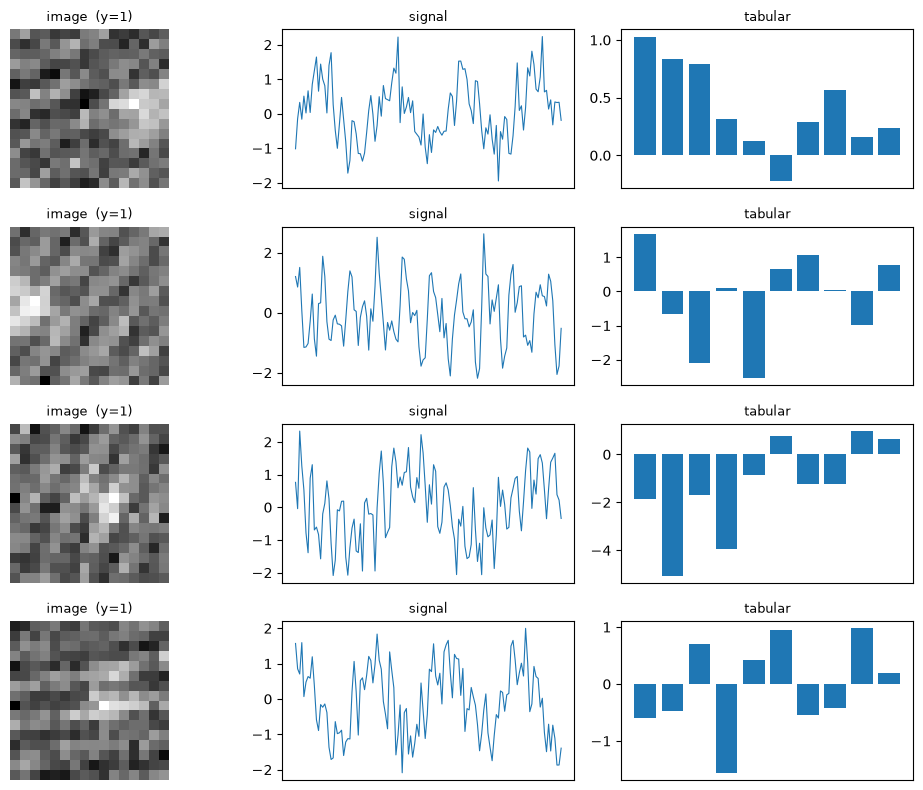

In [ ]:
def load(scn, n=6000, noise=1.0, seed=0):
    return split_dataset(make_dataset(scn, n=n, noise=noise, seed=seed), (0.6, 0.2, 0.2), seed=seed)

for scn in SCENARIOS:
    print(make_dataset(scn, n=4000).summary())

tr, va, te = load("C")
fig = plot_samples(tr, n=4); plt.show()

**Exercise 1 (TODO).** For each scenario, compute how well *each modality alone* could predict `y`, using the oracle
view of that modality: predict `y = 1` if `data.obs[:, m] > 0` (column 0 = image, 1 = signal, 2 = tabular).
This is an upper bound on unimodal accuracy for A, C, and a rough proxy for B, D.

**Predict first:** which scenario should give ~50% for *every* single modality, and why?

In [3]:
def unimodal_oracle(data):
    # TODO: return a list with the accuracy of sign(obs[:, m]) as predictor of data.y, for m = 0, 1, 2
    return [
        float(((data.obs[:, m] > 0).astype(int) == data.y).mean())
        for m in range(3)
    ]

for scn in SCENARIOS:
    d = make_dataset(scn, n=5000)
    print(scn, np.round(unimodal_oracle(d), 3), "| all-modality oracle:", round(d.oracle_accuracy(), 3))

A [0.786 0.785 0.799] | all-modality oracle: 0.869
B [0.692 0.696 0.633] | all-modality oracle: 0.852
C [0.5   0.493 0.502] | all-modality oracle: 0.915
D [0.751 0.708 0.513] | all-modality oracle: 0.885
E [0.786 0.785 0.799] | all-modality oracle: 0.869


c gives a small accuracy per scenario because its XOR label depends on both the image bit and signal bit; knowing either one alone does not reveal the answer.

## Part 2: The classical fusion grid with fixed features (sklearn)

Fixed features: flattened pixels, **FFT magnitudes** of the signal (its phase is random, so raw samples cannot be
used linearly), raw tabular values.

|  | Linear | Nonlinear |
|---|---|---|
| **Early** (concatenate features, one model) | logistic regression | MLP, gradient boosting |
| **Late** (combine unimodal predictions) | average of logits | stacking with a nonlinear meta-learner |

Complete the three TODO functions.

In [4]:
LR  = lambda: LogisticRegression(max_iter=3000, C=0.1)
MLP = lambda: MLPClassifier((64,), alpha=1e-2, max_iter=400, early_stopping=True, random_state=0)
GBM = lambda: HistGradientBoostingClassifier(max_iter=150, random_state=0)

def acc(logits_or_pred, y):
    z = np.asarray(logits_or_pred)
    pred = z if z.dtype.kind in "iub" else (z > 0)
    return float((pred.astype(int) == y).mean())

def fit_unimodal(tr, make_clf):
    f = handcrafted_features(tr)
    return {m: make_pipeline(StandardScaler(), make_clf()).fit(f[m], tr.y) for m in MODS}

def _score(pipe, X):
    if hasattr(pipe, "decision_function"): return pipe.decision_function(X)
    p = np.clip(pipe.predict_proba(X)[:, 1], 1e-4, 1 - 1e-4); return np.log(p / (1 - p))

def unimodal_logits(models, d, mods=MODS):
    f = handcrafted_features(d)
    return np.stack([_score(models[m], f[m]) for m in mods], 1)       # (N, len(mods))

In [5]:
def concat_features(d, mods=MODS):
    # TODO (EARLY fusion): concatenate the handcrafted features of the modalities in `mods`
    # along axis 1 and return a 2D array (N, total_features). Hint: np.hstack
    f = handcrafted_features(d)
    return np.hstack([f[m] for m in mods])

def late_average(models, d, mods=MODS):
    # TODO (LATE, linear): return the mean of the unimodal logits over `mods`  -> shape (N,)
    return unimodal_logits(models, d, mods).mean(axis=1)

def fit_stacker(models, va, make_meta):
    # TODO (LATE, nonlinear): fit a meta-learner on the unimodal logits of the VALIDATION set
    # (the unimodal models never saw it, so the logits are honest).
    # Return a function d -> predicted labels.
    X_meta = unimodal_logits(models, va)
    meta = make_meta().fit(X_meta, va.y)

    def predict(d):
        return meta.predict(unimodal_logits(models, d))

    return predict

In [6]:
def sk_grid(scn, n=6000, noise=1.0, seed=0, methods=None):
    tr, va, te = load(scn, n, noise, seed)
    want = lambda k: methods is None or k in methods
    res = {"oracle": te.oracle_accuracy()}
    uni = fit_unimodal(tr, LR)
    for m in MODS: res[f"uni-{m}"] = acc(unimodal_logits(uni, te, [m])[:, 0], te.y)
    for name, mk in [("early-linear", LR), ("early-MLP", MLP), ("early-GBM", GBM)]:
        if want(name):
            pipe = make_pipeline(StandardScaler(), mk()).fit(concat_features(tr), tr.y)
            res[name] = float((pipe.predict(concat_features(te)) == te.y).mean())
    if want("late-avg"):   res["late-avg"] = acc(late_average(uni, te), te.y)
    if want("late-stack"): res["late-stack"] = acc(fit_stacker(uni, va, GBM)(te), te.y)
    return res

t0 = time.time()
tab = pd.DataFrame({s: sk_grid(s) for s in "ABC"}).T
print(f"{time.time()-t0:.0f}s"); tab

16s


,oracle,uni-img,uni-sig,uni-tab,early-linear,early-MLP,early-GBM,late-avg,late-stack
A,0.866,0.736,0.785,0.792,0.843,0.847,0.850,0.853,0.824
B,0.850,0.682,0.686,0.640,0.828,0.826,0.832,0.802,0.788
C,0.928,0.509,0.481,0.499,0.507,0.898,0.881,0.501,0.509


**Predict, then read the table (A, B, C).**
1. Which methods should be close to the oracle in A? Is late fusion worse than early?
2. In B, does early linear beat the best unimodal model? By how much?
3. In C, every unimodal model is at chance. Can *late-stack* (a nonlinear meta-learner on unimodal logits) recover
   the label? Explain using what information the unimodal logits contain.
4. In C, do early-MLP / early-GBM on 300+ raw features find the interaction? If not, why would a high-dimensional input
   make a synergy hard to find (think: no marginal signal, many irrelevant features)?

1-Combining three noisy views should improve on a single modality. Early linear and late average should both be close to the oracle; I do not expect a large difference between them.
2-Early linear should clearly beat the best unimodal model because it can use the distinct useful information in all three modalities
3- I predict accuracy  should be low like near 50%. Each unimodal model sees only one XOR input, which alone does not predict the label. Its prediction score therefore gives the stacker little useful information.
4-They can learn XOR because they see image and signal features together and can model interactions. Whether they succeed with 306 features is what the experiment tests

## Part 3: Learned encoders and intermediate fusion (PyTorch)

One interface for everything: `encoders (per modality) -> fusion module -> prediction head`.
Only the fusion module changes between experiments.

In [7]:
class ImgEnc(nn.Module):
    def __init__(s, dim=32):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                              nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(4),
                              nn.Flatten(), nn.Linear(256, dim), nn.ReLU())
    def forward(s, x): return s.net(x)

class SigEnc(nn.Module):
    """FFT magnitude front-end + MLP. (Optional challenge: replace by a 1D CNN and compare.)"""
    def __init__(s, dim=32, bins=40):
        super().__init__(); s.bins = bins
        s.net = nn.Sequential(nn.Linear(bins, 64), nn.ReLU(), nn.Linear(64, dim), nn.ReLU())
    def forward(s, x):
        spec = torch.fft.rfft(x[:, 0], dim=1).abs()[:, :s.bins]
        return s.net(torch.log1p(spec))

class TabEnc(nn.Module):
    def __init__(s, dim=32, d_in=10):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, dim), nn.ReLU())
    def forward(s, x): return s.net(x)

ENC = {"img": ImgEnc, "sig": SigEnc, "tab": TabEnc}

**Fusion modules** take a list of embeddings `[z_img, z_sig, z_tab]` (each `(B, dim)`) and return a fused tensor of
size `out_dim`.

* `ConcatFusion` (given): concatenation. With a linear head this is *linear intermediate fusion*; with an MLP head it
  becomes nonlinear.
* **TODO** `GatedFusion`: project each embedding to `out` dims with `tanh`, compute per-modality weights
  `g = softmax(W [z_1; z_2; z_3])` (input-dependent!), return `sum_m g_m * h_m`.
* **TODO** `BilinearFusion` (tensor fusion): project each embedding to `proj` dims, **append a constant 1**, and take the
  outer product across modalities. The appended 1 keeps unimodal and pairwise terms in the result. Output size is
  `(proj+1) ** n_modalities`. This explicitly builds *multiplicative interactions*.

In [8]:
class ConcatFusion(nn.Module):
    def __init__(s, dims): super().__init__(); s.out_dim = sum(dims)
    def forward(s, zs): return torch.cat(zs, 1)

class GatedFusion(nn.Module):
    def __init__(s, dims, out=32):
        super().__init__()
        s.out_dim = out
        # TODO: define s.proj (ModuleList of Linear(d, out)) and s.gate = Linear(sum(dims), len(dims))
        s.proj = nn.ModuleList([nn.Linear(d, out) for d in dims])
        s.gate = nn.Linear(sum(dims), len(dims))
    def forward(s, zs):
        # TODO: h_m = tanh(proj_m(z_m)); g = softmax(gate(cat(zs))); return sum_m g[:, m] * h_m
        # also store s.last_gate = g.detach() so we can inspect the modality weights later
        hs = [torch.tanh(layer(z)) for layer, z in zip(s.proj, zs)]
        g = torch.softmax(s.gate(torch.cat(zs, dim=1)), dim=1)
        s.last_gate = g.detach()
        return (torch.stack(hs, dim=1) * g.unsqueeze(-1)).sum(dim=1)

class BilinearFusion(nn.Module):
    def __init__(s, dims, proj=8):
        super().__init__()
        s.out_dim = (proj + 1) ** len(dims)
        # TODO: s.proj = ModuleList of Linear(d, proj)
        s.proj = nn.ModuleList([nn.Linear(d, proj) for d in dims])
    def forward(s, zs):
        # TODO: prepend/append a column of ones to each projected embedding, then fold the outer products:
        #   out = h_1; for h in rest: out = (out[:, :, None] * h[:, None, :]).flatten(1)
        hs = [
            torch.cat([layer(z), z.new_ones((z.shape[0], 1))], dim=1)
            for layer, z in zip(s.proj, zs)
        ]
        out = hs[0]
        for h in hs[1:]:
            out = (out[:, :, None] * h[:, None, :]).flatten(1)
        return out

In [9]:
class FusionNet(nn.Module):
    def __init__(s, fusion="concat", mods=MODS, dim=32, head="linear"):
        super().__init__()
        s.mods = list(mods)
        s.enc = nn.ModuleDict({m: ENC[m](dim) for m in s.mods})
        dims = [dim] * len(s.mods)
        s.fusion = {"concat": ConcatFusion, "gated": GatedFusion, "bilinear": BilinearFusion}[fusion](dims)
        k = s.fusion.out_dim
        s.head = nn.Linear(k, 1) if head == "linear" else nn.Sequential(nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(s, batch, mask=None):
        zs = [s.enc[m](batch[m]) for m in s.mods]
        if mask is not None:                       # mask: (B, M) of 0/1, zeroes dropped embeddings
            zs = [z * mask[:, i:i + 1] for i, z in enumerate(zs)]
        return s.head(s.fusion(zs)).squeeze(1)

def n_params(model): return sum(p.numel() for p in model.parameters())

**Training loop.** Complete `modality_mask`: with probability `p`, each modality of each sample is dropped
(mask 0), but **at least one modality must always survive** per sample. This is *modality dropout*.

In [10]:
def modality_mask(B, M, p):
    # TODO: return a float tensor (B, M); entry = 0 with probability p, else 1.
    # Rows that came out all-zero must get one random modality switched back on.
    mask = (torch.rand(B, M) >= p).float()
    empty_rows = torch.where(mask.sum(dim=1) == 0)[0]

    if len(empty_rows):
        columns = torch.randint(M, (len(empty_rows),))
        mask[empty_rows, columns] = 1.0

    return mask

In [11]:
def to_batch(d, mods): return {m: torch.as_tensor(getattr(d, m)) for m in mods}

def fit(model, tr, epochs=25, lr=3e-3, bs=128, mod_dropout=0.0, seed=0, wd=1e-4):
    torch.manual_seed(seed)
    X, y = to_batch(tr, model.mods), torch.as_tensor(tr.y, dtype=torch.float32)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(y))
        for i in range(0, len(y), bs):
            b = perm[i:i + bs]
            mask = modality_mask(len(b), len(model.mods), mod_dropout) if mod_dropout > 0 else None
            loss = F.binary_cross_entropy_with_logits(model({m: X[m][b] for m in X}, mask), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return model

@torch.no_grad()
def predict_logits(model, d, bs=1024):
    model.eval(); X = to_batch(d, model.mods); n = len(d)
    return np.concatenate([model({m: X[m][i:i + bs] for m in X}).numpy() for i in range(0, n, bs)])

# quick smoke test
tr, va, te = load("A")
t0 = time.time(); m = fit(FusionNet("concat", MODS, head="linear"), tr, epochs=10)
print("A  concat+linear:", acc(predict_logits(m, te), te.y), f"({time.time()-t0:.0f}s, {n_params(m)} params)")

A  concat+linear: 0.8566666666666667 (3s, 17057 params)


In [12]:
def torch_suite(scn, n=6000, noise=1.0, seed=0, epochs=25, extra=None):
    tr, va, te = load(scn, n, noise, seed)
    res, logit_store, models = {"oracle": te.oracle_accuracy()}, {}, {}
    for m in MODS:                                        # unimodal networks
        net = fit(FusionNet("concat", [m]), tr, epochs); lg = predict_logits(net, te)
        res[f"uni-{m}"] = acc(lg, te.y); logit_store[m] = lg; models[m] = net
    res["late-avg"] = acc(np.mean([logit_store[m] for m in MODS], 0), te.y)
    configs = {"concat+linear": ("concat", "linear"), "concat+MLP": ("concat", "mlp"),
               "gated+MLP": ("gated", "mlp"), "bilinear+linear": ("bilinear", "linear")}
    for name, (fus, head) in configs.items():
        net = fit(FusionNet(fus, MODS, head=head), tr, epochs)
        res[name] = acc(predict_logits(net, te), te.y); models[name] = net
    return res, models, (tr, va, te)

t0 = time.time()
res_C, models_C, data_C = torch_suite("C")
print(f"{time.time()-t0:.0f}s"); pd.Series(res_C).to_frame("scenario C")

21s


,scenario C
oracle,0.928
uni-img,0.512
uni-sig,0.476
uni-tab,0.480
late-avg,0.491
concat+linear,0.482
concat+MLP,0.907
gated+MLP,0.911
bilinear+linear,0.914


**Predict then interpret (Scenario C).** Which of `concat+linear`, `concat+MLP`, `gated+MLP`, `bilinear+linear`
should reach the oracle? Why can a **linear head on a bilinear fusion** solve XOR while a linear head on a
concatenation cannot? Write the XOR in terms of the product `b_img * b_sig` (with bits coded as ±1).

Single-modality networks and late average: near 50%. One XOR input alone cannot determine the label.
Concat + linear head: near 50%. Its score adds separate effects from each modality; XOR requires an interaction.
Concat + MLP head: well above 50%, because the nonlinear head can combine image and signal embeddings.
Gated + MLP head: well above 50%, because its weights depend on the inputs and its head is nonlinear.
Bilinear + linear head: well above 50%. Bilinear fusion supplies product features, so even a linear head can use an interaction.
bilinear fusion creates a feature representing bimg bsig. The head only needs to give that feature a negative weight. A linear head on concatenated embeddings can only add a separate image term and signal term; it has no product term to express XOR.

## Part 4: Scenarios A and B with learned encoders

Run the same suite on A and B and compare to Part 2. Is learning the encoders worth it when fixed features already
capture the label? Look at the parameter counts and training time too.

In [13]:
rows = {}
for s in "AB":
    rows[s] = torch_suite(s)[0]
pd.DataFrame(rows)

,A,B
oracle,0.866,0.850
uni-img,0.761,0.687
uni-sig,0.777,0.673
uni-tab,0.793,0.634
late-avg,0.858,0.822
concat+linear,0.863,0.840
concat+MLP,0.848,0.837
gated+MLP,0.788,0.824
bilinear+linear,0.845,0.839


In A, all modalities observe the same underlying variable. Both approaches combine their noisy views effectively; concat+linear reaches 0.863, close to the 0.866 oracle. The learned gated model scores only 0.788, showing that a more complex fusion module does not automatically help.
In B, each modality holds different useful information; unimodal scores 0.687, while concat+linear reaches 0.840. The important improvement comes from combining modalities; learning the encoders adds relatively little beyond Part 2’s fixed-feature models.

The cost is much larger. A fixed-feature logistic model has 307 trainable parameters, versus 17,057 for learned concat+linear wich is 56 times as many. The learned concat+MLP, gated+MLP, and bilinear+linear models have 23,233, 22,596, and 18,482 parameters . 

## Part 5: Scenario D, modality imbalance

In D, `y` needs both the image (clean, easy) *and* the signal (noisy, harder to learn). A jointly trained network
learns the easy modality first and may under-train the other one.

**Exercise 2 (TODO).** Implement `pretrain_then_fuse`: train each unimodal network, copy its encoder into a fused
model, then fine-tune the whole model briefly with a lower learning rate. Then compare three training recipes for the
*same* architecture (`concat+MLP`): joint from scratch, joint with modality dropout (0.3), pretrain-then-fuse.

We also measure each modality's contribution by **permutation importance**: shuffle one modality across the test set
and record the accuracy drop.

In [14]:
def pretrain_then_fuse(tr, fusion="concat", head="mlp", epochs=25):
    # TODO: 1) for each m in MODS train FusionNet("concat", [m]) on tr
    #       2) build model = FusionNet(fusion, MODS, head=head) and load each encoder: model.enc[m].load_state_dict(...)
    #       3) fine-tune with fit(model, tr, epochs // 2, lr=1e-3) and return it
    unimodal = {
        m: fit(FusionNet("concat", [m]), tr, epochs=epochs)
        for m in MODS
    }

    model = FusionNet(fusion, MODS, head=head)
    for m in MODS:
        model.enc[m].load_state_dict(unimodal[m].enc[m].state_dict())

    return fit(model, tr, epochs=max(1, epochs // 2), lr=1e-3)


def perm_importance(model, d, seed=0):
    # TODO: baseline = accuracy on d; for each modality in MODS, shuffle that modality across samples
    # (np.random.default_rng(seed).permutation), recompute accuracy, return {m: baseline - shuffled_acc}
    baseline = acc(predict_logits(model, d), d.y)
    rng = np.random.default_rng(seed)
    importance = {}

    for m in MODS:
        shuffled = d.copy()
        setattr(
            shuffled, m,
            getattr(shuffled, m)[rng.permutation(len(d))]
        )
        shuffled_acc = acc(predict_logits(model, shuffled), d.y)
        importance[m] = baseline - shuffled_acc

    return importance

In [15]:
tr, va, te = load("D")
recipes = {
    "joint":              lambda: fit(FusionNet("concat", MODS, head="mlp"), tr, 25),
    "joint + mod-dropout": lambda: fit(FusionNet("concat", MODS, head="mlp"), tr, 25, mod_dropout=0.3),
    "pretrain-then-fuse": lambda: pretrain_then_fuse(tr),
}
rows = {}
for name, make in recipes.items():
    net = make(); r = {"acc": acc(predict_logits(net, te), te.y)}
    r.update({f"drop|{k}": v for k, v in perm_importance(net, te).items()})
    rows[name] = r
print("oracle:", round(te.oracle_accuracy(), 3)); pd.DataFrame(rows).T

oracle: 0.858


,acc,drop|img,drop|sig,drop|tab
joint,0.823,0.215,0.127,0.002
joint + mod-dropout,0.838,0.210,0.153,0.005
pretrain-then-fuse,0.832,0.207,0.153,0.002


**Discuss.** Which modality has the largest permutation importance under joint training? Does modality dropout or
pretraining raise the importance of the weaker (signal) modality, and does accuracy follow? (Differences may be
small, so repeat with a few seeds before concluding.)

Under joint training, the image has the largest permutation importance. Across three seeds, shuffling it reduced accuracy by 0.234 on average, compared with 0.162 for the signal and approximately 0 for tabular data.
In seed 0, both modality dropout and pretraining increased signal importance and accuracy. That pattern did not hold across seeds: mean signal importance was 0.152 with dropout (below joint training’s 0.162) and 0.164 with pretraining (almost the same). Mean accuracy rose slightly, from 0.843 for joint training to 0.848 with dropout and 0.849 with pretraining.
So the image remains the dominant modality. The small accuracy gains do not provide consistent evidence that either recipe makes the model rely more on the weaker signal.

## Part 6: Scenario E, robustness to corruption and missing modalities

Train on clean data from E (redundant modalities), then test on corrupted copies using
`corrupt(data, modality, mode, level)`: `mode="noise"` adds noise of std `level` times the modality's std;
`mode="drop"` zeroes the modality for a fraction `level` of the samples.

Models: joint `concat+MLP` (no dropout), joint `concat+MLP` with modality dropout 0.3, and **late fusion** that
averages unimodal logits over the modalities that are *available*.

**Exercise 3 (TODO).** Fill in `robustness`.
**Predict:** which model collapses when the image is dropped? Which one degrades gracefully?

In [16]:
tr, va, te = load("E")
joint      = fit(FusionNet("concat", MODS, head="mlp"), tr, 25)
joint_drop = fit(FusionNet("concat", MODS, head="mlp"), tr, 25, mod_dropout=0.3)
unis       = {m: fit(FusionNet("concat", [m]), tr, 25) for m in MODS}

def late_predict(d, missing=()):
    avail = [m for m in MODS if m not in missing]
    return np.mean([predict_logits(unis[m], d) for m in avail], 0)

predictors = {
    "joint":           lambda d, missing=(): predict_logits(joint, d),
    "joint+mod-drop":  lambda d, missing=(): predict_logits(joint_drop, d),
    "late-avg":        late_predict,
}
conditions = [("clean", None, None, 0), ("img dropped", "img", "drop", 1.0),
              ("sig dropped", "sig", "drop", 1.0), ("tab dropped", "tab", "drop", 1.0),
              ("sig noise x2", "sig", "noise", 2.0), ("sig noise x5", "sig", "noise", 5.0)]

In [17]:
def robustness(predictors, conditions, te):
    # TODO: for every condition (name, modality, mode, level):
    #   - build the test set: te itself for 'clean', else corrupt(te, modality, mode, level)
    #   - missing = (modality,) if mode == 'drop' else ()   (late fusion knows what is missing)
    #   - for each predictor compute acc(pred(d_test, missing), te.y)
    # return a DataFrame with conditions as rows and predictors as columns
    rows = {}

    for name, modality, mode, level in conditions:
        d_test = te if modality is None else corrupt(te, modality, mode, level)
        missing = (modality,) if mode == "drop" else ()

        rows[name] = {
            model_name: acc(predict(d_test, missing), te.y)
            for model_name, predict in predictors.items()
        }

    return pd.DataFrame.from_dict(rows, orient="index")

I would expect the joint model trained only on clean data to lose the most when an input disappears. The dropout-trained model has practiced using fewer modalities, while late average can explicitly omit a known missing modality. Because E gives all three modalities information about the label, I would predict degradation rather than assume any model must collapse. Added noise may behave differently: late average still includes a noisy modality because it is present.

## Part 7: Sweeps (noise and sample efficiency)

**Exercise 4 (TODO).** (a) *Noise sweep:* in scenario A, increase `noise` and plot `early-linear` vs `late-avg`
accuracy (use `sk_grid(..., methods=["early-linear", "late-avg"])`). (b) *Sample efficiency in C:* accuracy of
`early-MLP` (sklearn) and `bilinear+linear` (torch) vs. training-set size. The generator is the same, only `n` changes.

**Predict:** in (b), which method needs fewer samples to detect the XOR interaction?

A: More noise should reduce oracle and model accuracy. Early linear and late average should be fairly close because both combine redundant views.
C: Bilinear fusion should need fewer examples to find XOR: its product features explicitly represent an image–signal interaction. The early MLP must discover that interaction among 306 input features.

,oracle,early-linear,late-avg
noise,,,
0.500,0.932,0.917,0.922
1.000,0.866,0.843,0.853
1.500,0.808,0.778,0.780
2.000,0.760,0.720,0.716
3.000,0.690,0.642,0.645


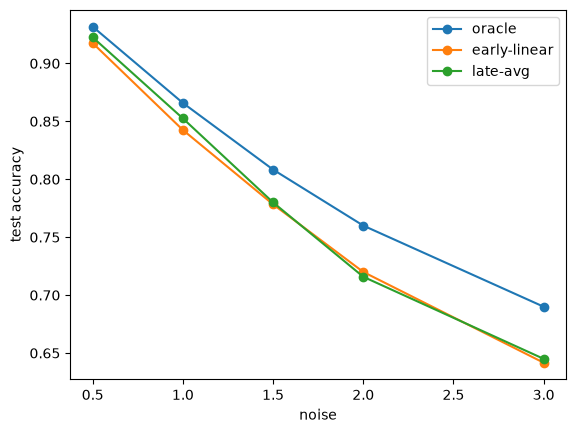

,early-MLP,bilinear+linear
n_train,,
360,0.500,0.575
900,0.743,0.897
2400,0.873,0.907
6000,0.882,0.889


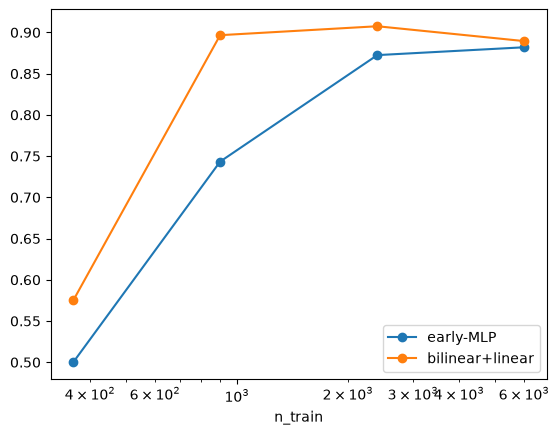

In [18]:
def noise_sweep(scn, noises, methods=("early-linear", "late-avg")):
    # TODO: return a DataFrame indexed by noise with one column per method (and the oracle)
    rows = []
    for noise in noises:
        result = sk_grid(scn, noise=noise, methods=methods)
        rows.append({
            "noise": noise,
            "oracle": result["oracle"],
            **{method: result[method] for method in methods}
        })
    return pd.DataFrame(rows).set_index("noise")

def sample_efficiency_C(ns, epochs=25):
    # TODO: for each n in ns: ds = load("C", n=n); fit sklearn early-MLP on concat_features and a torch
    # FusionNet("bilinear", MODS, head="linear"); evaluate both on the test split.
    # return a DataFrame indexed by training size n_train with columns ['early-MLP', 'bilinear+linear']
    rows = []
    for n in ns:
        tr, va, te = load("C", n=n)

        early = make_pipeline(
            StandardScaler(), MLP()
        ).fit(concat_features(tr), tr.y)
        early_acc = float(
            (early.predict(concat_features(te)) == te.y).mean()
        )

        neural = fit(
            FusionNet("bilinear", MODS, head="linear"),
            tr,
            epochs=epochs
        )
        neural_acc = acc(predict_logits(neural, te), te.y)

        rows.append({
            "n_train": len(tr),
            "early-MLP": early_acc,
            "bilinear+linear": neural_acc
        })

    return pd.DataFrame(rows).set_index("n_train")

sw = noise_sweep("A", [0.5, 1.0, 1.5, 2.0, 3.0]); display(sw); sw.plot(marker="o"); plt.ylabel("test accuracy"); plt.show()
se = sample_efficiency_C([600, 1500, 4000, 10000]); display(se); se.plot(marker="o", logx=True); plt.show()

## Part 8: Open challenge, design your own scenario

Use `make_dataset(..., sigma=(img, sig, tab))` to set per-modality noise, or copy `make_dataset` and change how `y`
is built from the latents. Ideas:

* **Partial synergy:** `y = XOR(b_img, b_sig)` *or* `s` (a mixture of redundancy and synergy).
* **Hidden modality:** make the tabular vector informative only for one class.
* **Conflicting modalities:** the image says "1", the signal says "0" for 20% of samples. Who should win?
* **Asymmetric noise sweep:** keep the image clean and degrade only the signal.

Fill in your hypothesis *before* running:

| My scenario | Information structure | Predicted best fusion | Why | Observed |
|---|---|---|---|---|
| | | | | |

**Reflection questions**
1. Why is Scenario C impossible for decision-level fusion regardless of the meta-learner?
2. When is the cheapest method (late average) also the best?
3. What does your result say about the common practice "just concatenate and train"?
4. What would change with real data (non-i.i.d. noise, label noise, correlated modalities)?

## asymmetric noise 
image = 0.2       signal = 0.2, 0.8, 1.5, or 3.0       tabular = 0.8

,oracle,uni-img,uni-sig,uni-tab,late-avg,early-linear,late-weighted,weight-sig
sig_sigma,,,,,,,,
0.200,0.958,0.927,0.926,0.794,0.952,0.946,0.955,0.599
0.800,0.946,0.927,0.775,0.794,0.933,0.934,0.936,0.258
1.500,0.944,0.927,0.673,0.794,0.932,0.932,0.933,0.150
3.000,0.944,0.927,0.590,0.794,0.931,0.931,0.933,0.066


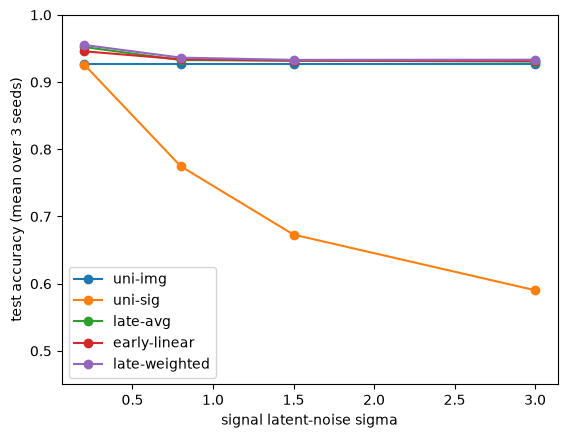

In [19]:
def asymmetric_redundancy(sig_sigma, seed=0, n=6000):
    data = make_dataset(
        "A", n=n, seed=seed,
        sigma=(0.2, sig_sigma, 0.8)
    )
    return split_dataset(data, (0.6, 0.2, 0.2), seed=seed)


def evaluate_asymmetric(sig_sigma, seed=0, n=6000):
    tr, va, te = asymmetric_redundancy(sig_sigma, seed, n)

    # Three models trained separately, one per modality.
    uni = fit_unimodal(tr, LR)
    logits_te = unimodal_logits(uni, te)

    # Early fusion: one classifier on all fixed features.
    early = make_pipeline(
        StandardScaler(), LR()
    ).fit(concat_features(tr), tr.y)

    # Learned late fusion: train its weights on validation logits.
    weighted = LogisticRegression(max_iter=3000, C=0.1).fit(
        unimodal_logits(uni, va), va.y
    )

    return {
        "sig_sigma": sig_sigma,
        "seed": seed,
        "oracle": te.oracle_accuracy(),
        "uni-img": acc(logits_te[:, 0], te.y),
        "uni-sig": acc(logits_te[:, 1], te.y),
        "uni-tab": acc(logits_te[:, 2], te.y),
        "late-avg": acc(logits_te.mean(axis=1), te.y),
        "early-linear": float(
            (early.predict(concat_features(te)) == te.y).mean()
        ),
        "late-weighted": float(
            (weighted.predict(logits_te) == te.y).mean()
        ),
        "weight-sig": float(weighted.coef_[0, 1]),
    }


sigmas = [0.2, 0.8, 1.5, 3.0]

results = pd.DataFrame([
    evaluate_asymmetric(sig_sigma, seed)
    for seed in (0, 1, 2)
    for sig_sigma in sigmas
])

metrics = [
    "oracle", "uni-img", "uni-sig", "uni-tab",
    "late-avg", "early-linear", "late-weighted", "weight-sig"
]
means = results.groupby("sig_sigma")[metrics].mean()
display(means.round(3))

means[
    ["uni-img", "uni-sig", "late-avg",
     "early-linear", "late-weighted"]
].plot(marker="o")
plt.xlabel("signal latent-noise sigma")
plt.ylabel("test accuracy (mean over 3 seeds)")
plt.ylim(0.45, 1.0)
plt.show()

The main prediction holds: signal-only accuracy drops from 0.926 to 0.590, while image-only stays at 0.927. The learned late model reduces its mean coefficient on the signal logit from 0.599 to 0.066.
The surprise is that equal late averaging also remains strong. As the signal becomes less predictive, its separately trained classifier generally supplies less useful, smaller-magnitude logits. At the highest noise, weighted late averages 0.933 versus 0.931 for equal late and early linear. That difference is too small to declare a reliable winner.

1. Why can’t decision-level fusion solve Scenario C, regardless of its meta-learner?
In C, the two fair, independent bits determine XOR. Knowing only the image bit—or only the signal bit—leaves  P(y=1)=0.5. An ideal unimodal classifier therefore outputs probability 0.5, or logit 0. The late meta-learner receives those label-prediction scores, not the original bits. No nonlinear function of constant scores can recover XOR. 
2. When can cheap late averaging be best?
It works especially well when modalities provide redundant, reasonably reliable evidence and their prediction scores are comparably calibrated. Averaging can cancel independent errors without training a joint model. It can also omit a modality known to be missing, as in Part 6.  a weak unimodal classifier may naturally produce less influential logits. A confidently wrong or poorly calibrated classifier could still spoil the average
3. What does this say about “just concatenate and train”?
Concatenation worked well in A and B because the supplied features exposed useful information. But a linear model on concatenated features could not express C’s XOR interaction. A nonlinear model could learn it, though Part 7 showed it needed more examples than bilinear fusion under these settings. Parts D and E add further concerns: a joint model can favor an easier modality, and clean-test performance does not tell us how it behaves under missing or corrupted inputs. 
4. What changes with real data
Modalities may share the same errors, so averaging gives less benefit. Noise can change across sites or time; labels can be wrong; missing inputs can be systematic; and measurements may be misaligned. There is also no synthetic oracle to consult. Evaluation should use realistic held-out groups or periods, relevant corruption and missingness tests, and multiple splits or seeds